# 5 · Evaluation: Schlägt das Gate die Baselines?

Ausgewertet werden nur **Out-of-Sample-Prognosen** aus 04: die Testzeilen jedes Folds. Experten, Baselines und Gates stehen auf **denselben Zeilen**.

| Metrik | Definition | gut ist |
|---|---|---|
| **QLIKE** | $\frac{y}{\hat\mu} - \ln\frac{y}{\hat\mu} - 1$ (Patton 2011, robust gegenüber verrauschten Vola-Proxies) | 0 |
| **Pinball** | Mittel über die 21 Quantile | klein |
| **Cov90** | Anteil $q_{0.05} \le y \le q_{0.95}$ | ≈ 0.90 |
| **rel_\*** | Metrik / Metrik des Random Walk pro Serie, geometrisches Mittel über die Serien | < 1 |
| **Diebold-Mariano** | Test auf QLIKE-Differenzen, Newey-West-Varianz | DM < 0 und p < 0.05: erstes Modell signifikant besser |

`TARGET = "true_var"` (nur synthetische Daten) wertet gegen die wahre Varianz statt gegen die verrauschte RV aus.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASET = "binance"        # Name aus 01_daten.ipynb, z.B. "binance" oder "syn_regime_signal_s0"

DATA_DIR, RESULTS_DIR = Path("data"), Path("results")
INFO = json.loads((DATA_DIR / f"{DATASET}.json").read_text())
DAILY_DIR, FORECAST_DIR = Path(INFO["daily_dir"]), Path(INFO["forecast_dir"])
SIDS = INFO["sids"]
SYNTHETIC = INFO["info"]["source"] == "synthetic"
print(f"Datensatz {DATASET}: {len(SIDS)} Serien {SIDS}")

QUANTILES = [0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5,
             0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]   # = native Chronos-2-Quantile
QCOLS = [f"q{q:.2f}" for q in QUANTILES]
_LV = np.asarray(QUANTILES)

from statistics import NormalDist

RUN = f"{DATASET}_walkforward"   # Ordner in results/runs/
BASELINE = "RW"                  # Referenz für rel_*
TARGET = "y"                     # "y" (gemessene RV) oder "true_var" (nur synthetisch)

RUN_DIR = RESULTS_DIR / "runs" / RUN
CONFIG = json.loads((RUN_DIR / "config.json").read_text())
POOL = CONFIG["POOL"]

Datensatz binance: 3 Serien ['BTCUSDT', 'ETHUSDT', 'SOLUSDT']


## Laden und scoren

Der Random Walk wird aus den Expertenprognosen dazugeholt, falls er nicht ohnehin im Pool ist.

In [2]:
def qlike(y, f):
    r = y / f
    return r - np.log(r) - 1


def pinball(y, Q):
    d = y[:, None] - Q
    return np.mean(np.maximum(_LV * d, (_LV - 1) * d), axis=1)


fc = pd.read_parquet(RUN_DIR / "forecasts.parquet")
weights = pd.read_parquet(RUN_DIR / "weights.parquet")
METHODS = [m for m in fc["model"].unique() if m not in POOL]

if BASELINE not in POOL:
    keys = fc[["sid", "h", "origin", "fold"] + [c for c in ["true_var", "regime"] if c in fc]].drop_duplicates()
    rw = pd.concat([pd.read_parquet(FORECAST_DIR / f"{sid}__{BASELINE}.parquet") for sid in SIDS])
    rw = rw.drop(columns="split", errors="ignore").merge(keys, on=["sid", "h", "origin"])
    fc = pd.concat([fc, rw[fc.columns]], ignore_index=True)

y = fc[TARGET].to_numpy()
fc["qlike"] = qlike(y, fc["mean"].to_numpy())
fc["pinball"] = pinball(y, fc[QCOLS].to_numpy())
fc["cov90"] = (fc[TARGET] >= fc["q0.05"]) & (fc[TARGET] <= fc["q0.95"])
fc["logerr"] = np.log(fc[TARGET] / fc["mean"])

ORDER = [BASELINE] + [m for m in POOL if m != BASELINE] + METHODS
n = fc[fc["model"] == POOL[0]].groupby("h").agg(Zeilen=("y", "size"), von=("target_date", "min"),
                                                bis=("target_date", "max"), Folds=("fold", "nunique"))
display(n)

,Zeilen,von,bis,Folds
h,,,,
1,360,2025-11-01,2026-02-28,4
5,360,2025-11-01,2026-02-28,4


## 1. Übersicht

Relativ zum Random Walk (< 1 = besser), geometrisches Mittel über die Serien.

In [3]:
gmean = lambda x: float(np.exp(np.log(x).mean()))

agg = (fc.groupby(["sid", "h", "model"])
         .agg(QLIKE=("qlike", "mean"), Pinball=("pinball", "mean"), Cov90=("cov90", "mean"))
         .reset_index())
base = agg.loc[agg["model"] == BASELINE, ["sid", "h", "QLIKE", "Pinball"]]
agg = agg.merge(base, on=["sid", "h"], suffixes=("", "_base"))
agg["rel_QLIKE"] = agg["QLIKE"] / agg["QLIKE_base"]
agg["rel_Pinball"] = agg["Pinball"] / agg["Pinball_base"]

summary = (agg.groupby(["h", "model"])
              .agg(rel_QLIKE=("rel_QLIKE", gmean), rel_Pinball=("rel_Pinball", gmean),
                   QLIKE=("QLIKE", "mean"), Cov90=("Cov90", "mean")))
summary = summary.reindex(pd.MultiIndex.from_product([sorted(fc["h"].unique()), ORDER], names=["h", "model"]))
display(summary.round(3))
display(agg.pivot_table(index=["sid", "h"], columns="model", values="rel_QLIKE")[ORDER].round(3))

rel_QLIKE  rel_Pinball  QLIKE  Cov90
h model                                                       
1 RW                          1.000        1.000  0.367  0.858
  Chronos-2-full              0.542        0.766  0.199  0.897
  TimesFM-2.5                 0.520        0.730  0.191  0.847
  HAR                         0.669        0.902  0.246  0.878
  GARCH                       0.917        1.063  0.341  0.853
  Gleichgewicht               0.578        0.802  0.212  0.889
  Auswahl                     0.520        0.730  0.191  0.847
  Inverse Fehler              0.559        0.788  0.205  0.892
  Inverse Fehler 90T          0.560        0.786  0.206  0.883
  Inverse jüngste Fehler      0.546        0.791  0.200  0.881
  Statisch                    0.510        0.740  0.187  0.894
  Statisch 365T               0.526        0.751  0.193  0.903
  Gating linear               0.498        0.773  0.182  0.894
  Gating linear [recent]      0.507        0.749  0.186  0.883
  Gating linear [market]      0.497        0.783  0.182  0.878
  Gating MLP                  0.489        0.755  0.179  0.900
5 RW                          1.000        1.000  0.679  0.864
  Chronos-2-full              0.503        0.669  0.337  0.878
  TimesFM-2.5                 0.565        0.667  0.380  0.833
  HAR                         0.562        0.724  0.377  0.831
  GARCH                       0.587        0.757  0.394  0.808
  Gleichgewicht               0.492        0.675  0.330  0.850
  Auswahl                     0.565        0.667  0.380  0.833
  Inverse Fehler              0.491        0.674  0.329  0.853
  Inverse Fehler 90T          0.494        0.675  0.331  0.850
  Inverse jüngste Fehler      0.502        0.675  0.336  0.847
  Statisch                    0.488        0.664  0.327  0.844
  Statisch 365T               0.507        0.669  0.340  0.858
  Gating linear               0.506        0.672  0.340  0.847
  Gating linear [recent]      0.486        0.667  0.326  0.847
  Gating linear [market]      0.501        0.664  0.336  0.842
  Gating MLP                  0.523        0.685  0.352  0.833

model       RW  Chronos-2-full  TimesFM-2.5    HAR  GARCH  Gleichgewicht  \
sid     h                                                                  
BTCUSDT 1  1.0           0.491        0.491  0.650  0.817          0.518   
        5  1.0           0.415        0.507  0.493  0.529          0.419   
ETHUSDT 1  1.0           0.541        0.532  0.676  1.129          0.631   
        5  1.0           0.496        0.556  0.551  0.583          0.484   
SOLUSDT 1  1.0           0.601        0.538  0.682  0.836          0.592   
        5  1.0           0.620        0.641  0.652  0.655          0.588   

model      Auswahl  Inverse Fehler  Inverse Fehler 90T  \
sid     h                                                
BTCUSDT 1    0.491           0.502               0.500   
        5    0.507           0.417               0.414   
ETHUSDT 1    0.532           0.602               0.608   
        5    0.556           0.483               0.490   
SOLUSDT 1    0.538           0.577               0.579   
        5    0.641           0.587               0.595   

model      Inverse jüngste Fehler  Statisch  Statisch 365T  Gating linear  \
sid     h                                                                   
BTCUSDT 1                   0.498     0.466          0.477          0.473   
        5                   0.431     0.422          0.419          0.461   
ETHUSDT 1                   0.570     0.527          0.534          0.477   
        5                   0.495     0.481          0.501          0.487   
SOLUSDT 1                   0.571     0.540          0.572          0.547   
        5                   0.591     0.571          0.619          0.578   

model      Gating linear [recent]  Gating linear [market]  Gating MLP  
sid     h                                                              
BTCUSDT 1                   0.479                   0.461       0.454  
        5                   0.416                   0.447       0.488  
ETHUSDT 1                   0.478                   0.509       0.474  
        5                   0.479                   0.494       0.506  
SOLUSDT 1                   0.571                   0.523       0.545  
        5                   0.576                   0.569       0.578

## 2. Vergleich mit den Baselines (Diebold-Mariano)

Jede Methode gegen **Gleichgewicht**, **Statisch** und den **besten Experten** (pro Horizont). Gepoolt über die Serien: Pro Ursprung wird der QLIKE über die Serien gemittelt, dann wird auf der Zeitreihe der Differenzen getestet.

**dQLIKE %** < 0: die Methode ist besser. Ein Gate lohnt sich erst, wenn es **Statisch** und die Baselines ohne Parameter signifikant schlägt.

In [4]:
def dm_test(d, h):
    # Diebold-Mariano auf Loss-Differenzen d, HAC-Varianz nach Newey-West
    d = np.asarray(d, float)
    d = d[np.isfinite(d)]
    T, u = len(d), d - d.mean()
    lag = max(h - 1, 1)
    var = u @ u / T + 2 * sum((1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lag + 1))
    stat = d.mean() / np.sqrt(var / T)
    return stat, 2 * (1 - NormalDist().cdf(abs(stat)))


def compare(methods, against, by_series=False):
    L = fc.pivot_table(index=["sid", "h", "origin"], columns="model", values="qlike")
    rows = []
    for key, g in (L.groupby(level=["sid", "h"]) if by_series else L.groupby(level="h")):
        h = key[1] if by_series else key
        if not by_series:
            g = g.groupby(level="origin").mean()
        for a in methods:
            for b in against(h) if callable(against) else against:
                if a == b:
                    continue
                stat, p = dm_test(g[a] - g[b], h)
                rows.append({**({"sid": key[0]} if by_series else {}), "h": h, "Methode": a, "gegen": b,
                             "dQLIKE %": round(100 * (g[a].mean() - g[b].mean()) / g[b].mean(), 2),
                             "DM": round(stat, 2), "p": round(p, 3)})
    return pd.DataFrame(rows)


best_expert = {int(h): summary.loc[h].loc[POOL, "QLIKE"].idxmin() for h in sorted(fc["h"].unique())}
against = lambda h: [m for m in ["Gleichgewicht", "Statisch"] if m in METHODS] + [best_expert[h]]
cmp = compare([m for m in METHODS if m not in ("Gleichgewicht", "Statisch")], against)
print("Bester Experte:", best_expert)
display(cmp.pivot_table(index=["h", "Methode"], columns="gegen", values=["dQLIKE %", "p"], sort=False))

Bester Experte: {1: 'TimesFM-2.5', 5: 'Chronos-2-full'}


/var/folders/fc/r822p1_s5v5_mswzrz420sj00000gn/T/ipykernel_49977/3855448968.py:8: RuntimeWarning: invalid value encountered in scalar divide
  stat = d.mean() / np.sqrt(var / T)


dQLIKE %                                      \
gegen                    Gleichgewicht Statisch TimesFM-2.5 Chronos-2-full   
h Methode                                                                    
1 Auswahl                       -10.22     2.08        0.00            NaN   
  Inverse Fehler                 -3.42     9.82        7.58            NaN   
  Inverse Fehler 90T             -3.17    10.10        7.85            NaN   
  Inverse jüngste Fehler         -5.85     7.05        4.87            NaN   
  Statisch 365T                  -9.30     3.13        1.02            NaN   
  Gating linear                 -14.23    -2.47       -4.46            NaN   
  Gating linear [recent]        -12.58    -0.60       -2.62            NaN   
  Gating linear [market]        -14.29    -2.55       -4.53            NaN   
  Gating MLP                    -15.68    -4.12       -6.07            NaN   
5 Auswahl                        15.03    15.99         NaN          12.51   
  Inverse Fehler                 -0.23     0.60         NaN          -2.42   
  Inverse Fehler 90T              0.43     1.26         NaN          -1.78   
  Inverse jüngste Fehler          1.97     2.82         NaN          -0.27   
  Statisch 365T                   2.94     3.80         NaN           0.68   
  Gating linear                   2.94     3.80         NaN           0.68   
  Gating linear [recent]         -1.18    -0.35         NaN          -3.35   
  Gating linear [market]          1.87     2.72         NaN          -0.36   
  Gating MLP                      6.57     7.46         NaN           4.23   

                                     p                                      
gegen                    Gleichgewicht Statisch TimesFM-2.5 Chronos-2-full  
h Methode                                                                   
1 Auswahl                        0.590    0.766         NaN            NaN  
  Inverse Fehler                 0.002    0.476       0.706            NaN  
  Inverse Fehler 90T             0.005    0.465       0.696            NaN  
  Inverse jüngste Fehler         0.032    0.568       0.794            NaN  
  Statisch 365T                  0.523    0.146       0.861            NaN  
  Gating linear                  0.304    0.355       0.512            NaN  
  Gating linear [recent]         0.270    0.863       0.781            NaN  
  Gating linear [market]         0.187    0.684       0.698            NaN  
  Gating MLP                     0.216    0.068       0.441            NaN  
5 Auswahl                        0.593    0.437         NaN          0.433  
  Inverse Fehler                 0.514    0.937         NaN          0.870  
  Inverse Fehler 90T             0.790    0.846         NaN          0.897  
  Inverse jüngste Fehler         0.655    0.489         NaN          0.982  
  Statisch 365T                  0.819    0.544         NaN          0.866  
  Gating linear                  0.761    0.270         NaN          0.938  
  Gating linear [recent]         0.800    0.929         NaN          0.785  
  Gating linear [market]         0.874    0.542         NaN          0.961  
  Gating MLP                     0.542    0.054         NaN          0.658

Dasselbe pro Serie, für die Gates gegen Statisch. Hängt ein Gewinn nur an einer Serie, ist er wenig robust.

In [5]:
gates = [m for m in METHODS if m.startswith("Gating")]
if "Statisch" in METHODS and gates:
    display(compare(gates, ["Statisch"], by_series=True)
            .pivot_table(index=["sid", "h"], columns="Methode", values=["dQLIKE %", "p"]))

dQLIKE %                                       \
Methode   Gating MLP Gating linear Gating linear [market]   
sid     h                                                   
BTCUSDT 1      -2.52          1.50                  -0.97   
        5      15.57          9.05                   5.73   
ETHUSDT 1     -10.05         -9.53                  -3.48   
        5       5.10          1.10                   2.64   
SOLUSDT 1       0.88          1.28                  -3.17   
        5       1.27          1.15                  -0.47   

                                          p                \
Methode   Gating linear [recent] Gating MLP Gating linear   
sid     h                                                   
BTCUSDT 1                   2.80      0.144         0.739   
        5                  -1.44      0.047         0.156   
ETHUSDT 1                  -9.37      0.040         0.091   
        5                  -0.40      0.192         0.740   
SOLUSDT 1                   5.71      0.741         0.698   
        5                   0.90      0.686         0.750   

                                                         
Methode   Gating linear [market] Gating linear [recent]  
sid     h                                                
BTCUSDT 1                  0.883                  0.265  
        5                  0.472                  0.702  
ETHUSDT 1                  0.612                  0.363  
        5                  0.538                  0.931  
SOLUSDT 1                  0.608                  0.087  
        5                  0.875                  0.806

## 3. Lohnt sich Gating überhaupt? Oracle und Fehlerkorrelation

- **Oracle:** wählt rückblickend jeden Tag den besten Experten. Obergrenze für jedes Gate.
- **max. Gewinn %:** Abstand zwischen bestem Einzelmodell und Oracle.
- **Oracle-Beitrag m:** mittleres $\max(0, \min_{k \ne m} L_k - L_m)$. Nahe null heisst: Der Experte ist überflüssig.
- **Fehlerkorrelation:** Liegen alle Experten gleichzeitig in dieselbe Richtung daneben, gibt es wenig zu routen.

In [6]:
L = fc[fc["model"].isin(POOL)].pivot_table(index=["sid", "h", "origin"], columns="model", values="qlike")[POOL]
rep = {}
for h, Lh in L.groupby(level="h"):
    ml = Lh.mean()
    best = ml.idxmin()
    row = {"bestes Einzelmodell": best, "QLIKE bestes": ml[best], "QLIKE Oracle": Lh.min(axis=1).mean()}
    row["max. Gewinn %"] = 100 * (ml[best] - row["QLIKE Oracle"]) / ml[best]
    wins = Lh.idxmin(axis=1).value_counts(normalize=True)
    row.update({f"Winrate {m}": wins.get(m, 0.0) for m in POOL})
    row.update({f"Oracle-Beitrag {m}": np.maximum(0, Lh.drop(columns=m).min(axis=1) - Lh[m]).mean() for m in POOL})
    rep[f"h={h}"] = row
display(pd.DataFrame(rep))

E = fc[fc["model"].isin(POOL)].pivot_table(index=["sid", "h", "origin"], columns="model", values="logerr")[POOL]
for h, Eh in E.groupby(level="h"):
    print(f"h={h}: Korrelation der Log-Fehler")
    display(Eh.corr().round(2))

,h=1,h=5
bestes Einzelmodell,TimesFM-2.5,Chronos-2-full
QLIKE bestes,0.190742,0.337321
QLIKE Oracle,0.088901,0.157367
max. Gewinn %,53.392091,53.347879
Winrate Chronos-2-full,0.236111,0.205556
Winrate TimesFM-2.5,0.375,0.375
Winrate HAR,0.163889,0.172222
Winrate GARCH,0.225,0.247222
Oracle-Beitrag Chronos-2-full,0.008688,0.026426
Oracle-Beitrag TimesFM-2.5,0.016631,0.031769


h=1: Korrelation der Log-Fehler


model,Chronos-2-full,TimesFM-2.5,HAR,GARCH
model,,,,
Chronos-2-full,1.00,0.98,0.80,0.69
TimesFM-2.5,0.98,1.00,0.81,0.71
HAR,0.80,0.81,1.00,0.84
GARCH,0.69,0.71,0.84,1.00


h=5: Korrelation der Log-Fehler


model,Chronos-2-full,TimesFM-2.5,HAR,GARCH
model,,,,
Chronos-2-full,1.00,0.99,0.88,0.81
TimesFM-2.5,0.99,1.00,0.86,0.80
HAR,0.88,0.86,1.00,0.93
GARCH,0.81,0.80,0.93,1.00


## 4. Was lernen die Kombinationen?

Mittlere Gewichte pro Methode. Bei synthetischen Daten zusätzlich **pro Regime**: Ein Gate, das die Regimes erkennt, sollte im Regime 1 (persistent) dem RW mehr Gewicht geben und im Regime 0 (mean-reverting) dem HAR.

In [7]:
show = [m for m in ["Statisch", "Inverse jüngste Fehler", "Gating linear", "Gating MLP"] if m in METHODS]
display(weights[weights["model"].isin(show)].groupby(["h", "model"])[POOL].mean().round(3))
if "regime" in weights:
    display(weights[weights["model"].isin(show)].groupby(["h", "model", "regime"])[POOL].mean().round(3))

Chronos-2-full  TimesFM-2.5    HAR  GARCH
h model                                                            
1 Gating MLP                       0.369        0.490  0.000  0.140
  Gating linear                    0.359        0.545  0.019  0.077
  Inverse jüngste Fehler           0.294        0.306  0.223  0.177
  Statisch                         0.389        0.547  0.000  0.064
5 Gating MLP                       0.206        0.454  0.109  0.232
  Gating linear                    0.354        0.353  0.151  0.142
  Inverse jüngste Fehler           0.273        0.283  0.222  0.222
  Statisch                         0.160        0.621  0.023  0.197

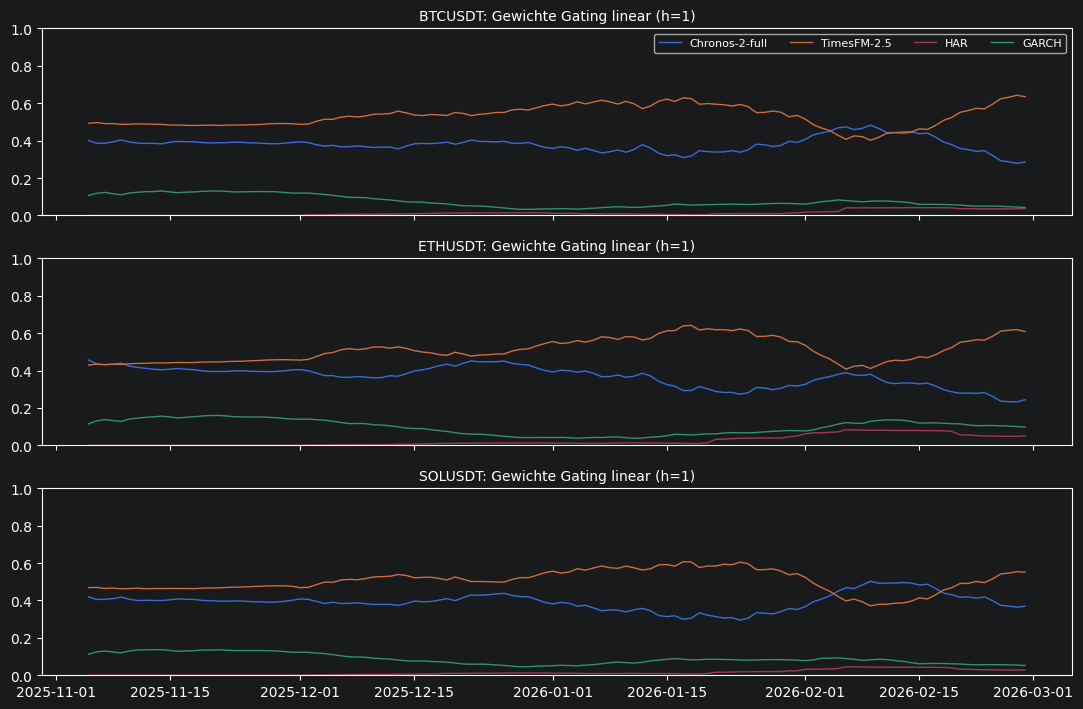

In [8]:
# Gewichte des linearen Gates über die Zeit (h=1, gleitendes 30-Tage-Mittel), Linien = Neutraining
gw = weights[(weights["model"] == "Gating linear") & (weights["h"] == min(weights["h"]))]
sids = gw["sid"].unique()
fig, axes = plt.subplots(len(sids), 1, figsize=(11, 2.4 * len(sids)), sharex=True, squeeze=False)
for ax, sid in zip(axes[:, 0], sids):
    d = gw[gw["sid"] == sid].set_index("target_date").sort_index()
    for m in POOL:
        ax.plot(d[m].rolling(30, min_periods=5).mean(), label=m, lw=1)
    if "regime" in d and d["regime"].nunique() > 1:
        ax.fill_between(d.index, 0, 1, where=d["regime"] == d["regime"].max(), color="grey", alpha=0.15,
                        transform=ax.get_xaxis_transform())
    ax.set_ylim(0, 1)
    ax.set_title(f"{sid}: Gewichte Gating linear (h={min(weights['h'])})", fontsize=10)
axes[0, 0].legend(ncol=len(POOL), fontsize=8)
plt.tight_layout()
plt.show()

### Welche Features treiben das lineare Gate?

Koeffizienten $W$ auf standardisierten Features, gemittelt über die Folds. Positiv: Ein hoher Feature-Wert erhöht das Gewicht dieses Experten. Bei einem grossen gewählten λ sind alle Koeffizienten nahe 0.

In [9]:
coef_path = RUN_DIR / "coef.parquet"
if coef_path.exists():
    coef = pd.read_parquet(coef_path)
    for h, c in coef.groupby("h"):
        print(f"h={h}")
        display(c.groupby("feature", sort=False)[POOL].mean().round(3))

h=1


,Chronos-2-full,TimesFM-2.5,HAR,GARCH
feature,,,,
logrv_dev,-0.231,0.042,0.201,-0.012
trend,0.185,-0.390,0.058,0.148
level_rel,0.096,0.305,0.166,-0.568
volvol,-0.174,0.076,-0.250,0.348
ret1,-0.137,0.484,-0.529,0.182
ret5,-0.123,0.164,-0.366,0.325
disagree_Chronos-2-full,-0.132,0.216,-0.107,0.022
disagree_TimesFM-2.5,0.100,-0.255,-0.217,0.371
disagree_HAR,-0.337,0.092,0.005,0.240


h=5


,Chronos-2-full,TimesFM-2.5,HAR,GARCH
feature,,,,
logrv_dev,0.106,-0.128,-0.095,0.117
trend,-0.412,0.026,-0.099,0.486
level_rel,0.141,0.441,0.225,-0.806
volvol,-0.202,0.333,-0.175,0.043
ret1,-0.022,0.199,0.018,-0.195
ret5,-0.220,0.117,0.146,-0.043
disagree_Chronos-2-full,-0.111,0.132,0.152,-0.173
disagree_TimesFM-2.5,-0.084,-0.225,-0.071,0.381
disagree_HAR,-0.169,-0.069,0.198,0.041
